# Финальная оценка на test

Чекпоинт `checkpoints/best.pt`: двунаправленная LSTM, замороженный Navec и выкидывание слов при обучении. Модель выбирали по val, F1-macro 0.644. Ниже один проход по `data/processed/test.csv`, без дообучения.

Запускать из корня репозитория.

In [1]:
import json
from pathlib import Path

import torch

from src.evaluate import format_summary, predict_file, summarize
from src.models.rnn import model_from_checkpoint

checkpoint = Path("checkpoints/best.pt")
model = model_from_checkpoint(checkpoint)
payload = torch.load(checkpoint, map_location="cpu", weights_only=False)
records = predict_file(model, Path("data/processed/test.csv"))
summary = summarize(records)
baseline = json.loads(Path("reports/baseline.json").read_text(encoding="utf-8"))
print(
    format_summary(
        summary,
        baseline_f1=baseline["test"]["logistic_regression"]["f1_macro"],
        val_f1=payload["metrics"]["f1_macro"],
    )
)
print("Эпоха чекпоинта:", payload["epoch"])

Строк: 474. Ошибок: 154.
Accuracy 0.675, precision 0.685, recall 0.675, F1-macro 0.679.
Baseline на test, логистическая регрессия: F1-macro 0.612.
F1-macro на val у этого чекпоинта: 0.644.
По классам:
- негатив: precision 0.661, recall 0.686, f1 0.673, support 159
- нейтрально: precision 0.572, recall 0.627, f1 0.598, support 158
- позитив: precision 0.824, recall 0.713, f1 0.765, support 157
Матрица ошибок: [[109, 39, 11], [46, 99, 13], [10, 35, 112]]
Соседний класс: 133. Перескок негатив↔позитив: 21.
Сильнее всего позитив. Слабее всего нейтрально.
По сферам:
- отзывы о банках: accuracy 0.583, ошибок 25 из 60, чаще всего нейтрально → негатив (15)
- отзывы об аниме: accuracy 0.593, ошибок 24 из 59, чаще всего позитив → нейтрально (10)
- отзывы о фильмах: accuracy 0.667, ошибок 20 из 60, чаще всего позитив → нейтрально (6)
- отзывы на банковское приложение: accuracy 0.678, ошибок 19 из 59, чаще всего нейтрально → негатив (7)
- отзывы о местах: accuracy 0.700, ошибок 18 из 60, чаще всего

## Матрица ошибок

Строки — метка, столбцы — предсказание. Порядок классов: негатив, нейтрально, позитив.

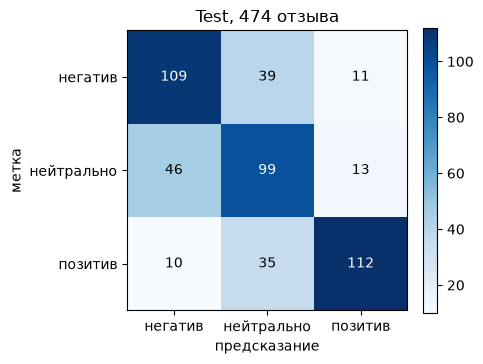

In [2]:
import matplotlib.pyplot as plt

from src.data.validate import LABEL_TITLES, VALID_LABELS

matrix = summary["metrics"]["confusion_matrix"]
names = [LABEL_TITLES[label] for label in VALID_LABELS]
peak = max(max(row) for row in matrix)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
image = ax.imshow(matrix, cmap="Blues")
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("предсказание")
ax.set_ylabel("метка")
ax.set_title("Test, 474 отзыва")
for row_index, row in enumerate(matrix):
    for col_index, value in enumerate(row):
        color = "white" if value > peak / 2 else "black"
        ax.text(col_index, row_index, str(value), ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()

## Ошибки

Для каждой пары «метка → предсказание» показаны самые уверенные промахи. Ниже — по одному самому уверенному верному ответу на класс.

In [3]:
from src.evaluate import format_examples

print(format_examples(summary))

Ошибки, в которых модель уверена:
- [нейтрально → негатив] 0.94, bank, 124 токенов
  «Просили оставить отзыв на службу поддержки клиентов банка МТС. Не вопрос. Буквально вчера, сделал заказ в интернет магазине МТС, оплата по обоим имеющимся картам МТС (Мастер и Кэш…»
- [нейтрально → негатив] 0.93, ru-reviews-classification, 65 токенов
  «Заказывала 11.11, получила 19.12, кошмар какой-то, судя по комментариям, все кто заказал 11.11 получили 29.11. Продавец тянул до последнего с отправкой заказа, оставалось меньше с…»
- [негатив → нейтрально] 0.73, perekrestok, 9 токенов
  «Слишком крупные. Лучше бы цуккини взяла, переплатив всего 20р.»
- [негатив → нейтрально] 0.72, rureviews, 17 токенов
  «В жизни выглядят отстойно, на стыках как бы веревочек видны нитки, которыми оные сшиты, носить не буду»
- [позитив → нейтрально] 0.79, rureviews, 7 токенов
  «тонкая маечка. чистая синтетика. но рисунок яркий.»
- [позитив → нейтрально] 0.75, geo, 19 токенов
  «Мясо в тарелке офигенное, все гармонично

## Что модель умеет и где путается

На test F1-macro **0.679**, accuracy 0.675. Это выше baseline логистической регрессии (0.612) и чуть выше val этого чекпоинта (0.644). До цели 0.80 по-прежнему далеко.

Сильнее всего позитив: F1 0.765, precision 0.824. Если модель ставит позитив, она чаще права. Из 154 ошибок 133 — соседний класс и только 21 — перескок негатив↔позитив. Явный негатив и явный позитив она узнаёт уверенно.

Слабее всего нейтральный класс: F1 0.598, precision 0.572. В матрице `[[109, 39, 11], [46, 99, 13], [10, 35, 112]]` нейтральные отзывы расходятся в обе стороны, а чужие классы часто падают в нейтральный. Типичный промах — смешанный текст: «колючая, но красивая», «заказ не получила, но деньги вернули», претензия со словом «спасибо». Модель хватает более яркую половину, а метка корпуса ставит середину или итог.

Хуже всего банки: accuracy 0.583, 25 ошибок из 60, чаще всего нейтрально → негатив. В примерах нейтральная метка стоит на тексте с претензией к поддержке, и модель читает претензию как негатив. Одежда на test не проваливается: accuracy 0.724.

Отзывы длиннее окна в 200 токенов слабее среднего: accuracy 0.619 на 21 строке. Английский отзыв без русских слов модель переворачивает. Похвала, внутри которой цитируют чужой негатив («10 из 10», «концовка не плохая»), тоже уезжает в негатив. Ручные метки пилота на test, 22 строки, почти как вся выборка: accuracy 0.682.